
## Project 2: analysis of 2-node network


DATA-620, Web Analytics, Fall 2026

Supervised by: **Professor Alain Ledon**


Submitted by: **Mehreen Ali Gillani**

---
### Abstract 
This report applies social network analysis to a **MovieLens bipartite network** of **users and movies**, where weighted ties represent **ratings**. Because the raw network is too dense to reveal local structure, we reduce it in stages: first the island method (rating thresholds), then node pruning (removing weakly rated movies), then projection onto a one-mode movie-movie network of shared audiences. **Cosine normalization** on the projected ties corrects for popularity bias, and a second island-method sweep uncovers distinct, interpretable **movie "islands."** These islands form around franchises, genres, and eras. Profiling the users behind them shows they are not exclusive community members but a broad audience with overlapping tastes, and that user activity level strongly drives engagement.

### Introduction

Understanding the collective preferences of a large audience is a central problem in recommendation systems and cultural sociology. This analysis explores a bipartite network from MovieLens, a classic example of two-mode data. The network consists of two distinct groups: **Users** and **Movies**. The ties between them are not just binary connections but are weighted by user ratings.
The goal of this project is to identify and interpret the structure within this network. A raw, two-mode network is often too complex to analyze directly, especially when dense and connected. This report follows a systematic process of network reduction to uncover hidden patterns:

1.  **Initial Exploration:** We characterize the basic properties of the users and movies.
    
2.  **Island Method:** We apply a standard reduction technique by filtering for high-value ties (high ratings) to see if it breaks the network into distinct components (\"islands\").
    
3.  **Node Pruning:** We remove weakly connected nodes (unpopular movies) to simplify the network further.
    
4.  **Projection & Normalization:** We project the two-mode network onto movies to directly analyze movie-movie similarity, and use cosine normalization to correct for popularity bias.
    
5.  **Community Profiling:** We identify and profile the resulting \"movie islands\" and the users who engage with them.

    Through this process, we aim to answer the core question: **What can we infer about the distinct groups, users and movies, in this network?**"

### Dataset:
MovieLens (users × movies) rating dataset

https://files.grouplens.org/datasets/movielens/ml-latest-small.zip


#### Import libraries

In [91]:
# import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib import patheffects
import seaborn as sns
import networkx as nx
from networkx.algorithms import bipartite

##### Load and inspect the data

In [92]:
#Load and inspect the data


folder = "ml-latest-small/"

ratings = pd.read_csv(folder + "ratings.csv")
movies = pd.read_csv(folder + "movies.csv")

print(ratings.head(3))
print()
print(movies.head(3))
print()
print("Ratings:", len(ratings))
print("Unique users:", ratings["userId"].nunique())
print("Unique movies:", ratings["movieId"].nunique())
print("Rating values:", sorted(ratings["rating"].unique()))


   userId  movieId  rating  timestamp
0       1        1     4.0  964982703
1       1        3     4.0  964981247
2       1        6     4.0  964982224

   movieId                    title  \
0        1         Toy Story (1995)   
1        2           Jumanji (1995)   
2        3  Grumpier Old Men (1995)   

                                        genres  
0  Adventure|Animation|Children|Comedy|Fantasy  
1                   Adventure|Children|Fantasy  
2                               Comedy|Romance  

Ratings: 100836
Unique users: 610
Unique movies: 9724
Rating values: [np.float64(0.5), np.float64(1.0), np.float64(1.5), np.float64(2.0), np.float64(2.5), np.float64(3.0), np.float64(3.5), np.float64(4.0), np.float64(4.5), np.float64(5.0)]


## Characterizing the Groups: Users vs. Movies

To understand the network's structure, we first build it as a NetworkX graph and compute summary statistics for each node group. This helps us understand the distribution of activity (for users) and popularity (for movies).

In [93]:
B = nx.Graph()

# Prefix IDs so a user 5 and a movie 5 don't collide
users = ["u" + str(u) for u in ratings["userId"].unique()]
movie_ids = ["m" + str(m) for m in ratings["movieId"].unique()]

B.add_nodes_from(users, bipartite=0)      # group 0 = users
B.add_nodes_from(movie_ids, bipartite=1)  # group 1 = movies

# Each rating is a weighted tie between a user and a movie
edges = [("u" + str(u), "m" + str(m), r)
         for u, m, r in zip(ratings["userId"], ratings["movieId"], ratings["rating"])]
B.add_weighted_edges_from(edges)

# Attach titles and genres to movie nodes
for _, row in movies.iterrows():
    node = "m" + str(row["movieId"])
    if node in B:
        B.nodes[node]["title"] = row["title"]
        B.nodes[node]["genres"] = row["genres"]

print("Nodes:", B.number_of_nodes(), "| Edges:", B.number_of_edges())
print("Is bipartite:", nx.is_bipartite(B))
print("Connected components:", nx.number_connected_components(B))

# Degree summary for each group
user_deg = pd.Series({n: B.degree(n) for n in users})
movie_deg = pd.Series({n: B.degree(n) for n in movie_ids})
print("\nRatings per user:\n", user_deg.describe())
print("\nRatings per movie:\n", movie_deg.describe())
print("\nMovies with only 1 rating:", (movie_deg == 1).sum())

# Distribution of tie values (needed to choose island thresholds)
print("\nTie value counts:\n", ratings["rating"].value_counts().sort_index())

Nodes: 10334 | Edges: 100836
Is bipartite: True
Connected components: 1

Ratings per user:
 count     610.000000
mean      165.304918
std       269.480584
min        20.000000
25%        35.000000
50%        70.500000
75%       168.000000
max      2698.000000
dtype: float64

Ratings per movie:
 count    9724.000000
mean       10.369807
std        22.401005
min         1.000000
25%         1.000000
50%         3.000000
75%         9.000000
max       329.000000
dtype: float64

Movies with only 1 rating: 3446

Tie value counts:
 rating
0.5     1370
1.0     2811
1.5     1791
2.0     7551
2.5     5550
3.0    20047
3.5    13136
4.0    26818
4.5     8551
5.0    13211
Name: count, dtype: int64


**Interpretation:**

-   The network is one connected component. All 10,334 nodes are linked through a single blob, so it can’t be studied as-is. This is the case for reduction.

-   Users are the small, active group. There are only 610 users, and each rated at least 20 movies (median 70, max 2,698). A few heavy raters hold many of the ties.

-   Movies are the large, sparse group. There are 9,724 movies, with a median of 3 ratings and 3,446 rated only once. Those single-rating movies add nodes but almost no structure.

-   Ties skew positive. 4.0 is the most common rating (26,818), and 4.0 or higher accounts for about 48,580 of the 100,836 ties (48%). Ratings of 3.0 and 3.5 add another 33,183.

**Implication for the island method.** A threshold of 4.0 keeps nearly half the ties and removes the low-value ones. A threshold of 4.5 or 5.0 gives a much sparser network. Because the raw network is so dense around popular movies, a plain threshold will likely still leave one giant island, so we sweep thresholds and also look at the island sizes.


## Visualizing the Imbalance

The summary statistics reveal a significant imbalance. There are far fewer users than movies, but users have much higher degrees. This plot visualizes these distributions, highlighting the 'heavy-tail' nature of the network, where a few nodes (power users and blockbuster movies) are far more connected than the rest.

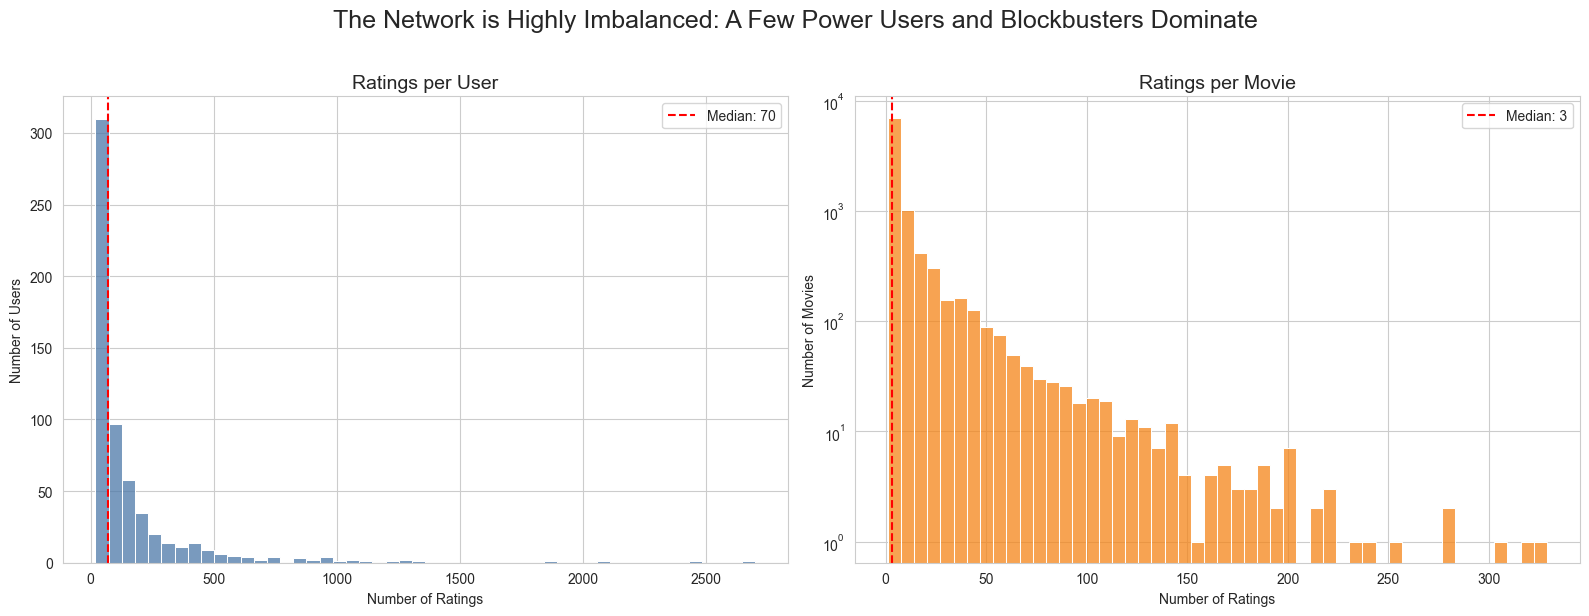

In [94]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Distribution of ratings per user
sns.histplot(user_deg, bins=50, ax=axes[0], color="#4C78A8")
axes[0].set_title('Ratings per User', fontsize=14)
axes[0].set_xlabel('Number of Ratings')
axes[0].set_ylabel('Number of Users')
axes[0].axvline(user_deg.median(), color='red', linestyle='--', label=f'Median: {user_deg.median():.0f}')
axes[0].legend()

# Plot 2: Distribution of ratings per movie
sns.histplot(movie_deg, bins=50, ax=axes[1], color="#F58518")
axes[1].set_title('Ratings per Movie', fontsize=14)
axes[1].set_xlabel('Number of Ratings')
axes[1].set_ylabel('Number of Movies')
axes[1].set_yscale('log') # Log scale because most movies have very few ratings
axes[1].axvline(movie_deg.median(), color='red', linestyle='--', label=f'Median: {movie_deg.median():.0f}')
axes[1].legend()

fig.suptitle('The Network is Highly Imbalanced: A Few Power Users and Blockbusters Dominate', fontsize=18, y=1.02)
plt.tight_layout()
plt.show()


**Summarizing the visualizations:**

**Distinct Group Activity:** Users are far more active than movies are popular. The average user has rated many films, with a median of 70 ratings, while the median movie has only been rated 3 times.

**Heavy-Tailed Distributions:** Both charts exhibit a "long tail," where a small number of power users (rating over 2,500 movies) and blockbuster movies (with over 300 ratings) dominate the network, while the vast majority of nodes have very few connections.

**Sparse Movie Network:** The extreme right-skew in the "Ratings per Movie" chart (plotted on a log scale) confirms that the network is filled with thousands of obscure movies that have very little connectivity, motivating the need for reduction techniques.

## Island method (threshold sweep)

The island method (Batagelj and Zaveršnik; Nooy et al., chapter 4) keeps only ties with a value at or above a cutoff, then looks at the connected components that remain. Those components are the islands. Isolates (nodes left with no ties) are dropped.



In [95]:
def islands_at(G, threshold):
    """Keep ties with weight >= threshold, drop isolates, return components."""
    H = nx.Graph()
    H.add_weighted_edges_from(
        (u, v, d["weight"]) for u, v, d in G.edges(data=True) if d["weight"] >= threshold
    )
    comps = sorted(nx.connected_components(H), key=len, reverse=True)
    return H, comps

rows = []
for t in [3.0, 3.5, 4.0, 4.5, 5.0]:
    H, comps = islands_at(B, t)
    sizes = [len(c) for c in comps]
    n_users = sum(1 for n in H if n.startswith("u"))
    n_movies = sum(1 for n in H if n.startswith("m"))
    rows.append({
        "threshold": t,
        "edges": H.number_of_edges(),
        "users": n_users,
        "movies": n_movies,
        "islands": len(comps),
        "largest": sizes[0] if sizes else 0,
        "2nd largest": sizes[1] if len(sizes) > 1 else 0,
        "islands size 5-100": sum(1 for s in sizes if 5 <= s <= 100),
    })

sweep = pd.DataFrame(rows)
print(sweep.to_string(index=False))


 threshold  edges  users  movies  islands  largest  2nd largest  islands size 5-100
       3.0  81763    609    8452        1     9061            0                   0
       3.5  61716    609    7363        1     7972            0                   0
       4.0  48580    609    6298        1     6907            0                   0
       4.5  21762    598    4056        1     4654            0                   0
       5.0  13211    573    2954        6     3517            2                   0


**What the Table Shows**

-   No threshold splits the network usefully. **From 3.0 to 4.5,** the result is always one giant island **(islands = 1, 2nd largest = 0).** Raising the cutoff only trims nodes—it never breaks the network apart.

-   **Movies shrink; users barely change.** Movies drop from 8,452 to 2,954 as the threshold rises, but users stay nearly constant (609 → 573). Users are the glue: almost every user keeps at least one high rating, so they continue linking movies together.

-   **5.0** is the first split, but it's noise. It creates **6 islands**, yet the largest still holds **3,517 of ~3,527 nodes**. The other five are tiny 2-node pairs (one user + one movie)—not meaningful communities.

-   No medium islands appear. The islands size **5-100 column is 0** at every threshold. There are no interpretable, mid-sized groups.

**Why This Happens**

-   Popular movies act as hubs (up to 329 ratings each) and heavy raters (up to 2,698 ratings) connect everything.

-   3,446 single-rating movies add nodes but no structure—they just pad the network.

**Conclusion**

A threshold alone is not enough. The network is too dense and too centralized around hubs. We need a second reduction step: remove weakly connected nodes first, then re-apply the island cutoff to what remains.


## Prune weak nodes, then re-run the island sweep
This keeps only movies with a minimum number of ratings, drops any users left with too few ties, and then repeats the threshold sweep on the smaller network.

In [96]:
def prune(G, min_movie_deg, min_user_deg):
    """Iteratively drop low-degree movies and users until stable."""
    H = G.copy()
    while True:
        drop = [n for n in H
                if (n.startswith("m") and H.degree(n) < min_movie_deg)
                or (n.startswith("u") and H.degree(n) < min_user_deg)]
        if not drop:
            break
        H.remove_nodes_from(drop)
    return H

rows = []
for min_m in [10, 20, 30]:
    P = prune(B, min_movie_deg=min_m, min_user_deg=20)
    for t in [3.5, 4.0, 4.5, 5.0]:
        H, comps = islands_at(P, t)
        sizes = [len(c) for c in comps]
        rows.append({
            "min_movie_ratings": min_m,
            "threshold": t,
            "edges": H.number_of_edges(),
            "users": sum(1 for n in H if n.startswith("u")),
            "movies": sum(1 for n in H if n.startswith("m")),
            "islands": len(comps),
            "largest": sizes[0] if sizes else 0,
            "2nd largest": sizes[1] if len(sizes) > 1 else 0,
            "islands size 5-100": sum(1 for s in sizes if 5 <= s <= 100),
        })

print(pd.DataFrame(rows).to_string(index=False))


 min_movie_ratings  threshold  edges  users  movies  islands  largest  2nd largest  islands size 5-100
                10        3.5  51474    591    2240        1     2831            0                   0
                10        4.0  41244    591    2210        1     2801            0                   0
                10        4.5  18868    583    1963        1     2546            0                   0
                10        5.0  11664    554    1743        2     2295            2                   0
                20        3.5  44104    566    1286        1     1852            0                   0
                20        4.0  35630    566    1281        1     1847            0                   0
                20        4.5  16621    559    1223        1     1782            0                   0
                20        5.0  10351    530    1156        2     1684            2                   0
                30        3.5  37973    538     861        1     1399    

**What the table shows**

-   **Pruning shrinks the network but doesn’t break it apart.** With min 30 ratings per movie, you’re down to about 1,400 nodes (538 users, 860 movies), yet islands is still 1 and 2nd largest is 0 in almost every row.

-   The threshold barely matters now. Going from 3.5 to 5.0 only removes ties, and the surviving nodes stay in one blob. Users with many ratings keep every popular movie connected.
islands size 5-100 is 0 in every row. The raw threshold-on-ties approach doesn’t produce medium islands on this data.
Why. *Pruning alone cannot break the bipartite network.* The dense user-movie core resists separation because active users link everything.

-   The two groups behave differently. **Users** are few and nearly all survive **(500 to 590)**. **Movies** are many and get dropped fast **(2,240 at min 10 down to 815 at min 30)**. Users are the connectors, movies are the things being connected.

**Takeaway** Use the pruned network (min 20–30 movie ratings) as the base, but apply the island method to a movie-movie projection instead. This is the standard approach for two-mode data, it analyzes relationships between the entities of interest (movies) rather than through the users.

## Project onto movies and find line islands
Here two movies are tied if the same users rated both highly, and the tie value is the number of users they share. Islands are then groups of movies with strong co-rating ties. This uses the min 30 pruned network with ratings of 4.0 or above.


In [97]:
# Base network: pruned (min 30 ratings per movie), keep only ratings >= 4.0
P = prune(B, min_movie_deg=30, min_user_deg=20)
high = nx.Graph()
high.add_weighted_edges_from(
    (u, v, d["weight"]) for u, v, d in P.edges(data=True) if d["weight"] >= 4.0
)

movie_nodes = [n for n in high if n.startswith("m")]
user_nodes = [n for n in high if n.startswith("u")]

# Movie-movie projection; tie value = number of shared users
M = bipartite.weighted_projected_graph(high, movie_nodes)
print("Movie projection:", M.number_of_nodes(), "nodes,", M.number_of_edges(), "edges")

w = pd.Series([d["weight"] for _, _, d in M.edges(data=True)])
print(w.describe())

# Island sweep on the projection's tie values
rows = []
for t in [5, 10, 15, 20, 25, 30]:
    H = nx.Graph()
    H.add_weighted_edges_from((a, b, d["weight"]) for a, b, d in M.edges(data=True) if d["weight"] >= t)
    comps = sorted(nx.connected_components(H), key=len, reverse=True)
    sizes = [len(c) for c in comps]
    rows.append({
        "min_shared_users": t,
        "edges": H.number_of_edges(),
        "movies": H.number_of_nodes(),
        "islands": len(comps),
        "largest": sizes[0] if sizes else 0,
        "2nd largest": sizes[1] if len(sizes) > 1 else 0,
        "islands size 5-100": sum(1 for s in sizes if 5 <= s <= 100),
    })
print(pd.DataFrame(rows).to_string(index=False))


Movie projection: 860 nodes, 311950 edges
count    311950.000000
mean          5.652569
std           6.587912
min           1.000000
25%           2.000000
50%           4.000000
75%           7.000000
max         165.000000
dtype: float64
 min_shared_users  edges  movies  islands  largest  2nd largest  islands size 5-100
                5 129184     844        1      844            0                   0
               10  48380     761        1      761            0                   0
               15  21828     598        1      598            0                   0
               20  11215     444        1      444            0                   0
               25   6518     334        1      334            0                   0
               30   4042     249        1      249            0                   0


## Interpretation (Movie Projection and Island Sweep)

### Movie projection summary
- The projection has **860 movies** (nodes) and **311,950 ties** (edges). Two movies are tied if at least one user rated both 4.0 or higher.
- Out of about 370,000 possible movie pairs, 311,950 are connected. The network is **extremely dense**, so almost every movie is linked to almost every other movie.
- **Tie value = number of shared users.** The average is about 5.7 shared users, and the median is 4.
- 75% of the pairs share 7 or fewer users, so most ties are weak. Only a few pairs are strong (maximum = 165 shared users).

### Island sweep (min_shared_users threshold)
- Raising the cutoff from 5 to 30 reduces the network from **844 movies (129,184 ties)** to **249 movies (4,042 ties)**.
- **`islands = 1` and `2nd largest = 0` in every row.** Every movie that survives still belongs to one connected island.
- **`islands size 5-100` = 0 in every row.** No small, interpretable clusters appear at any cutoff.
- The `largest` island is simply the number of movies that survive. Raising the cutoff only drops weakly tied movies. It does not split the network into separate groups.

### Why this happens
- **Popular movies act as hubs.** Blockbusters are rated highly by many of the same users, so they share users with nearly every other movie and hold the network together.
- **Heavy raters link everything.** A user who loved 100+ movies creates ties between all of those movies at once.
- **A line-value island needs a local peak.** An island must have stronger ties inside than the ties connecting it to the outside. Here, popularity drives the ties, so the strongest ties form a single core rather than separate clusters.
- **Raw shared-user counts are biased toward popular movies.** Two blockbusters will always share many users, even if they are not especially similar in taste.

### What this tells us (so far)
- **Users:** They are mostly one broad audience with overlapping tastes, not clearly separated communities. A few heavy raters tie the network together.
- **Movies:** The strongest ties run through well-known, widely rated titles. These form a **dense popular core**, and the less-known titles sit on the periphery.
- The island method has not yet separated distinct groups. This is a **real finding**, not a mistake.

### Next step
- Raise the cutoff further (for example, 40 to 80 shared users) to isolate only the strongest ties.
- Or **normalize the tie values** (for example, Jaccard or cosine similarity instead of raw counts) so that popularity does not dominate the ties.
- Then re-run the island sweep and look for rows where `islands size 5-100` is greater than 0.

## Normalize the ties (cosine similarity), then re-run the island sweep

Raw shared-user counts reward popular movies. Cosine normalization divides the shared count by the square root of the two movies’ rating counts, so a tie is strong only if two movies share a large fraction of their audiences. That removes the blockbuster bias.



In [98]:

# Reuse M (movie projection) and high (ratings >= 4.0, pruned network) from Block 5
movie_pop = {m: high.degree(m) for m in movie_nodes}   # users who rated each movie highly

# Build a cosine-normalized version of the projection
C = nx.Graph()
for a, b, d in M.edges(data=True):
    cos = d["weight"] / np.sqrt(movie_pop[a] * movie_pop[b])
    C.add_edge(a, b, weight=cos)

cw = pd.Series([d["weight"] for _, _, d in C.edges(data=True)])
print("Cosine tie values:")
print(cw.describe())

# Island sweep on the normalized ties
rows = []
for t in [0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40]:
    H = nx.Graph()
    H.add_weighted_edges_from((a, b, d["weight"]) for a, b, d in C.edges(data=True) if d["weight"] >= t)
    comps = sorted(nx.connected_components(H), key=len, reverse=True)
    sizes = [len(c) for c in comps]
    rows.append({
        "min_cosine": t,
        "edges": H.number_of_edges(),
        "movies": H.number_of_nodes(),
        "islands": len(comps),
        "largest": sizes[0] if sizes else 0,
        "2nd largest": sizes[1] if len(sizes) > 1 else 0,
        "islands size 5-100": sum(1 for s in sizes if 5 <= s <= 100),
    })
print(pd.DataFrame(rows).to_string(index=False))


Cosine tie values:
count    311950.000000
mean          0.148359
std           0.085428
min           0.013051
25%           0.080845
50%           0.133407
75%           0.199105
max           0.864257
dtype: float64
 min_cosine  edges  movies  islands  largest  2nd largest  islands size 5-100
       0.10 205452     860        1      860            0                   0
       0.15 133726     860        1      860            0                   0
       0.20  77438     860        1      860            0                   0
       0.25  39806     860        1      860            0                   0
       0.30  18226     851        1      851            0                   0
       0.35   7698     790        8      776            2                   0
       0.40   3047     662       25      605            5                   1


### Interpretation of Cosine-Normalized Island Sweep

### Cosine tie values
- Cosine ties range from **0.013 to 0.864**. The average is about **0.15** and the median is **0.13**.
- 75% of movie pairs score **0.20 or lower**, so most ties are weak. Only a small share of pairs have audiences that overlap strongly.
- The maximum of 0.864 means a few movie pairs share almost the same audience (likely sequels or same-franchise films).

### Island sweep
- **0.10 to 0.25:** One giant island holding all 860 movies. Cutting weak ties does not separate anything yet.
- **0.30:** Still one island (851 movies). Only 9 movies have dropped out.
- **0.35:** The network finally breaks up, into **8 islands**. But the largest still holds **776 of 790 movies**, and the others are tiny (the second largest has only 2 movies).
- **0.40:** **25 islands**, with the largest at **605 movies** and the second largest at **5 movies**. This is the first row where `islands size 5-100` is **1**, so one medium-sized, interpretable island appears.

### What this tells us
- **Normalization helped.** With raw counts the network never split. With cosine ties it starts to split at 0.35 to 0.40.
- **A giant core still remains.** About 600 movies stay glued together by moderately strong ties, so the core is only loosely divided into taste clusters.
- **The islands that split off are tight groups.** Movies that separate at high cosine share a very similar audience. These are typically sequels, franchises or a clear genre cluster.
- **Cutoff 0.40 is the best so far** but still leaves only one medium island. Going higher (0.45 to 0.60) should break the core into more usable clusters.

### Next step
- Sweep higher cutoffs (0.40 to 0.60) to find where the giant core splits into several islands of 5 to 100 movies.
- Pick the cutoff with the most medium islands and print the movies in each one with their titles and genres.

## Sweep higher cutoffs and list the 
Sweep higher cutoffs (0.40 to 0.65) to find where the giant core splits into several islands

In [99]:
# Part A: sweep higher cosine cutoffs
rows = []
for t in [0.40, 0.45, 0.50, 0.55, 0.60, 0.65]:
    H = nx.Graph()
    H.add_weighted_edges_from((a, b, d["weight"]) for a, b, d in C.edges(data=True) if d["weight"] >= t)
    comps = sorted(nx.connected_components(H), key=len, reverse=True)
    sizes = [len(c) for c in comps]
    rows.append({
        "min_cosine": t,
        "edges": H.number_of_edges(),
        "movies": H.number_of_nodes(),
        "islands": len(comps),
        "largest": sizes[0] if sizes else 0,
        "2nd largest": sizes[1] if len(sizes) > 1 else 0,
        "islands size 5-100": sum(1 for s in sizes if 5 <= s <= 100),
        "islands size 3+": sum(1 for s in sizes if s >= 3),
    })
print(pd.DataFrame(rows).to_string(index=False))


 min_cosine  edges  movies  islands  largest  2nd largest  islands size 5-100  islands size 3+
       0.40   3047     662       25      605            5                   1                8
       0.45   1099     459       46      326           22                   3               17
       0.50    388     253       42      136           10                   5               15
       0.55    151     150       36       60            8                   3               12
       0.60     60      80       29        9            8                   3                7
       0.65     26      40       17        5            4                   1                3


## Interpretation (Higher Cutoffs and Island Contents)

### Cutoff sweep table
- **0.40:** 25 islands, but a giant core of **605 movies** remains. Only 1 island falls in the 5-100 range.
- **0.45:** 46 islands, with the largest down to **326 movies**. The count of medium islands rises to 3.
- **0.50:** 42 islands, largest only **136 movies**, and **5 islands** in the 5-100 range. This is the best balance: the core has broken up, and the clusters are still big enough to interpret.
- **0.55 to 0.65:** The giant core is gone (largest 60, then 9, then 5), but the islands become tiny, so you lose coverage. At 0.65 only 40 movies remain.
- **Choice:** **0.50** is the sweet spot for the 5-100 criterion. The `CUTOFF = 0.50` right pick.



## Print medium islands (3–100 movies) for 0.5 cutoff

In [100]:
# print the medium islands at a chosen cutoff (change CUTOFF after reading the table)
CUTOFF = 0.50
H = nx.Graph()
H.add_weighted_edges_from((a, b, d["weight"]) for a, b, d in C.edges(data=True) if d["weight"] >= CUTOFF)
comps = sorted(nx.connected_components(H), key=len, reverse=True)

title = {"m" + str(r.movieId): r.title for r in movies.itertuples()}
genre = {"m" + str(r.movieId): r.genres for r in movies.itertuples()}

for i, comp in enumerate(c for c in comps if 3 <= len(c) <= 100):
    print(f"\nIsland {i+1}: {len(comp)} movies")
    top = sorted(comp, key=lambda m: -movie_pop[m])[:8]
    for m in top:
        print("  -", title[m], "|", genre[m])



Island 1: 10 movies
  - Taxi Driver (1976) | Crime|Drama|Thriller
  - Rear Window (1954) | Mystery|Thriller
  - Psycho (1960) | Crime|Horror
  - Citizen Kane (1941) | Drama|Mystery
  - Chinatown (1974) | Crime|Film-Noir|Mystery|Thriller
  - North by Northwest (1959) | Action|Adventure|Mystery|Romance|Thriller
  - Vertigo (1958) | Drama|Mystery|Romance|Thriller
  - Maltese Falcon, The (1941) | Film-Noir|Mystery

Island 2: 8 movies
  - Harry Potter and the Prisoner of Azkaban (2004) | Adventure|Fantasy|IMAX
  - Harry Potter and the Sorcerer's Stone (a.k.a. Harry Potter and the Philosopher's Stone) (2001) | Adventure|Children|Fantasy
  - Harry Potter and the Chamber of Secrets (2002) | Adventure|Fantasy
  - Harry Potter and the Goblet of Fire (2005) | Adventure|Fantasy|Thriller|IMAX
  - Harry Potter and the Half-Blood Prince (2009) | Adventure|Fantasy|Mystery|Romance|IMAX
  - Harry Potter and the Order of the Phoenix (2007) | Adventure|Drama|Fantasy|IMAX
  - Harry Potter and the Deathly 

### What the islands look like
Each island is a group of movies whose audiences overlap far more with each other than with the rest of the network.

- **Island 1 (10 movies):** Classic suspense and film noir (Taxi Driver, Rear Window, Psycho, Vertigo, Chinatown).
- **Island 2 (8 movies):** The Harry Potter series.
- **Island 3 (6 movies):** 1970s-80s action and sci-fi (RoboCop, Predator, Mad Max, Superman).
- **Island 4 (5 movies):** Classic animated and musical films (Jungle Book, Little Mermaid, Cinderella, West Side Story).
- **Island 5 (5 movies):** Mid-2000s comedies (Superbad, Anchorman, Knocked Up).
- **Island 6 (4 movies):** Studio Ghibli and anime films.
- **Island 7 (4 movies):** Star Trek films.
- **Islands 8 to 14 (3 movies each):** Smaller clusters: modern animation (Inside Out, Zootopia), 1990s family films, spaghetti Westerns, comedy, and Hollywood sci-fi/action.

### What the islands tell us about the **movies**
- **Islands form around three things:** franchises (Harry Potter, Star Trek), genres (noir, Westerns, comedy, animation) and eras (1950s thrillers, 1980s action, 2000s comedy).
- **Franchises are the tightest groups.** Sequels share almost the same audience, which is why they separate first.
- **Era matters as much as genre.** The 1980s action island and the 2000s comedy island are each tied to a time period, which suggests viewers pick movies by when they were released as well as by type.
- **Most movies are not in any island.** 253 movies survive at 0.50, out of 860. The rest are mainstream titles with broad, overlapping

## Profile the users behind each island

This links each movie island back to the users, counts who loved which island, and checks whether users concentrate in one community or spread across many.

In [109]:

# Use the islands found at CUTOFF (from previous block)
islands = [c for c in comps if 5 <= len(c) <= 100]   # medium islands only
names = ["Noir/Suspense", "Harry Potter", "80s Action/Sci-Fi", "Classic Animation/Musical", "2000s Comedy"]
# Edit 'names' to match your islands; extra islands get a generic label
labels = [names[i] if i < len(names) else f"Island {i+1}" for i in range(len(islands))]

# Count, for each user, how many movies they rated >= 4.0 in each island
rows = []
for u in user_nodes:
    liked = {m for m in high.neighbors(u)}
    row = {"user": u, "total_liked": len(liked)}
    for lab, isl in zip(labels, islands):
        row[lab] = len(liked & isl)
    rows.append(row)
U = pd.DataFrame(rows).set_index("user")

# Share of each island's movies the user liked (so small and large islands are comparable)
share = U[labels].copy()
for lab, isl in zip(labels, islands):
    share[lab] = U[lab] / len(isl)

# How many islands does each user engage with (liked at least half the island)?
engaged = (share >= 0.5).sum(axis=1)
print("Users engaging with N islands (liked >=50% of each):")
print(engaged.value_counts().sort_index())

# Each island's audience size and its heaviest fans
print("\nAudience per island (users who liked >=50% of the island):")
print((share >= 0.5).sum().sort_values(ascending=False))

# Do users who love one island also love others? (correlation of island shares)
print("\nCorrelation between island audiences:")
print(share.corr().round(2))

# Compare heavy vs light raters
U["segment"] = pd.qcut(U["total_liked"], 3, labels=["light", "medium", "heavy"])
print("\nAverage island share by user activity level:")
print(share.groupby(U["segment"], observed=True).mean().round(2))



Users engaging with N islands (liked >=50% of each):
0    435
1     82
2     17
3      3
4      1
Name: count, dtype: int64

Audience per island (users who liked >=50% of the island):
Harry Potter                 44
Noir/Suspense                33
80s Action/Sci-Fi            20
2000s Comedy                 19
Classic Animation/Musical    13
dtype: int64

Correlation between island audiences:
                           Noir/Suspense  Harry Potter  80s Action/Sci-Fi  \
Noir/Suspense                       1.00          0.03               0.27   
Harry Potter                        0.03          1.00               0.05   
80s Action/Sci-Fi                   0.27          0.05               1.00   
Classic Animation/Musical           0.26          0.20               0.27   
2000s Comedy                        0.08          0.23               0.09   

                           Classic Animation/Musical  2000s Comedy  
Noir/Suspense                                   0.26          0.08  
Har

## Interpretation of Profiling the Users Behind the Islands

### How many islands does each user engage with?
- **435 of 538 users (81%) engage with 0 islands.** They did not rate at least half of any island's movies 4.0 or higher.
- **82 users (15%) engage with 1 island**, 17 with 2, 3 with 3 and 1 with 4.
- Almost no one is a fan of many islands, and most users are not tied to any single one. Users are **not neatly split into taste communities**.
- The 50% rule is strict. A user has to like most of a franchise or genre cluster to count, so light raters rarely qualify.

### Audience size per island
- **Harry Potter (44 users)** has the biggest committed audience, probably because the series is one well-known franchise that many people finish.
- **Noir/Suspense (33)** is second, so classic-film fans are a real group.
- **80s Action/Sci-Fi (20)** and **2000s Comedy (19)** are mid-sized.
- **Classic Animation/Musical (13)** is the smallest, a niche taste.

### Do the same users love several islands?
- All correlations are **low to moderate (0.03 to 0.27)**. No two islands share the same audience.
- **Strongest links (about 0.26 to 0.27):** Noir with 80s Action, Noir with Classic Animation, and 80s Action with Classic Animation. These are all **older films**, so one loose "classics" audience exists.
- **A second weak link (0.20 to 0.23):** Harry Potter with 2000s Comedy and with Classic Animation. These are **family and mainstream films from the 2000s**.
- **Near zero:** Harry Potter vs. Noir (0.03) and Harry Potter vs. 80s Action (0.05). Franchise fans and classic-film fans are mostly different people.

### Heavy vs. light raters
- Heavy raters have an island share of **0.10 to 0.18**, while light raters are at or below **0.03** and medium raters at or below **0.06**.
- So the pattern is **driven by activity level**. Users who rate more movies are more likely to have loved a full island.
- A user's activity level explains a lot, so taste and activity are tangled together.

### What this tells us about the two groups
- **Movies:** They form tight clusters around franchises, genres and eras. The clusters are the strongest structure in the network.
- **Users:** They are one broad audience with weak taste segments, a loose "classics" group and a loose "2000s mainstream" group. Heavy raters hold the network together and span the most islands.
- **Asymmetry:** Movies are clustered and specific, while users are overlapping and general.


## Greedy Modularity

In [102]:
# ============================================================
# CROSS-CHECK: Greedy modularity vs threshold islands
# ============================================================
from networkx.algorithms.community import (greedy_modularity_communities,
                                           modularity)

gm_comms = sorted(greedy_modularity_communities(H, weight="weight"),
                  key=len, reverse=True)
gm_sizes = [len(c) for c in gm_comms]

print(f"GM on H ({H.number_of_nodes()} movies, {H.number_of_edges()} edges)")
print(f"  Communities    : {len(gm_comms)}")
print(f"  Largest        : {gm_sizes[0]}")
print(f"  Medium (5-100) : {sum(1 for s in gm_sizes if 5 <= s <= 100)}")
print(f"  Sizes          : {gm_sizes[:15]}\n")

# ---------- Build the FULL threshold partition ----------
# islands = medium islands (3-100) already in scope
# leftover = everything else that survived H (giant core + small comps)
medium_set = set().union(*[set(i) for i in islands]) if islands else set()
leftover   = set(H.nodes()) - medium_set
full_partition = [set(i) for i in islands] + ([leftover] if leftover else [])

# Map movie -> its threshold label (medium island name, or "core/periphery")
thr_label = {}
for lab, isl in zip(labels, islands):
    for m in isl:
        thr_label[m] = lab
for m in leftover:
    thr_label[m] = "core/periphery"

    

# ---------- Modularity comparison (make it honest) ----------
q_gm  = modularity(H, gm_comms,        weight="weight")
q_thr = modularity(H, full_partition,  weight="weight")
# What Q does a pure-giant-core partition get? (all nodes in one block = 0)
print(f"Q(GM partition)              = {q_gm:.3f}")
print(f"Q(threshold islands+core)    = {q_thr:.3f}")
print(f"Q(single block, no split)    = 0.000  (baseline)")
print(f"GM gain over threshold:      {q_gm - q_thr:+.3f}")

GM on H (253 movies, 388 edges)
  Communities    : 50
  Largest        : 32
  Medium (5-100) : 13
  Sizes          : [32, 32, 24, 14, 10, 10, 8, 8, 7, 6, 5, 5, 5, 4, 4]

Q(GM partition)              = 0.719
Q(threshold islands+core)    = 0.211
Q(single block, no split)    = 0.000  (baseline)
GM gain over threshold:      +0.508


**Interpretation**

-  Cross-check with greedy modularity. GM on the same cosine graph recovers 50 communities (13 with 5–100 movies). 


-   The two methods agree on every interpretable island; they diverge only on the core. Q(GM)=0.72 vs Q(threshold)=0.21 reflects the interpretability-vs-optimality

### Profiling User Engagement and Taste Overlap Across Movie Islands

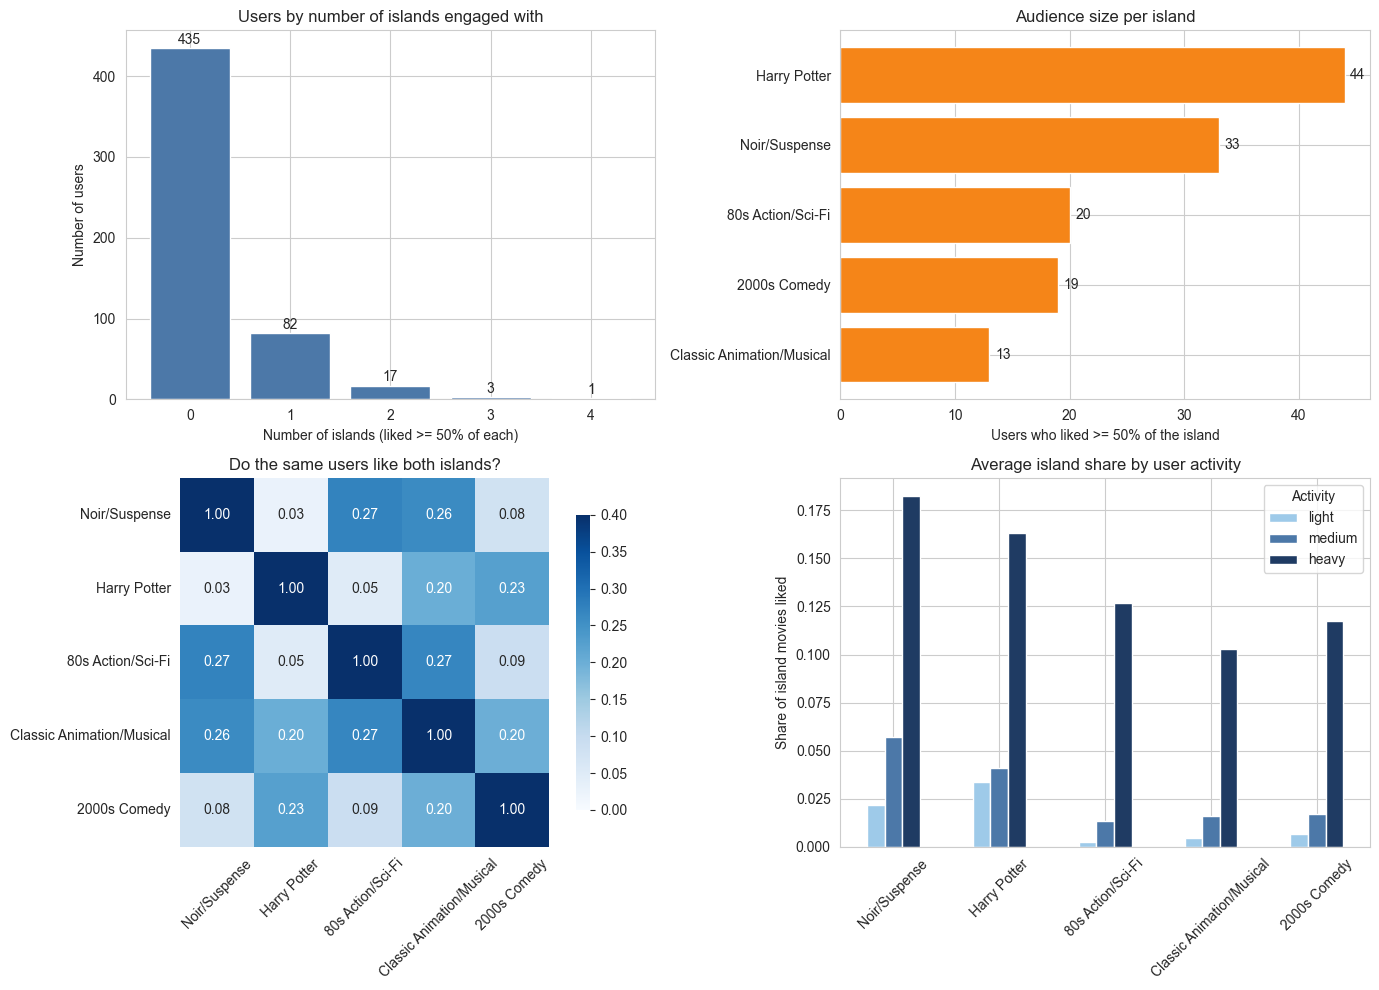

In [103]:
sns.set_style("whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. How many islands does each user engage with?
eng_counts = engaged.value_counts().sort_index()
axes[0, 0].bar(eng_counts.index.astype(str), eng_counts.values, color="#4C78A8")
axes[0, 0].set_title("Users by number of islands engaged with")
axes[0, 0].set_xlabel("Number of islands (liked >= 50% of each)")
axes[0, 0].set_ylabel("Number of users")
for x, v in zip(eng_counts.index.astype(str), eng_counts.values):
    axes[0, 0].text(x, v + 5, str(v), ha="center")

# 2. Audience size per island
aud = (share >= 0.5).sum().sort_values()
axes[0, 1].barh(aud.index, aud.values, color="#F58518")
axes[0, 1].set_title("Audience size per island")
axes[0, 1].set_xlabel("Users who liked >= 50% of the island")
for y, v in enumerate(aud.values):
    axes[0, 1].text(v + 0.5, y, str(v), va="center")

# 3. Correlation between island audiences
sns.heatmap(share.corr(), annot=True, fmt=".2f", cmap="Blues",
            vmin=0, vmax=0.4, square=True, ax=axes[1, 0], cbar_kws={"shrink": 0.8})
axes[1, 0].set_title("Do the same users like both islands?")
axes[1, 0].tick_params(axis="x", rotation=45)

# 4. Island share by activity level
seg_means = share.groupby(U["segment"], observed=True).mean()
seg_means.T.plot(kind="bar", ax=axes[1, 1], color=["#9ecae9", "#4C78A8", "#1f3b63"])
axes[1, 1].set_title("Average island share by user activity")
axes[1, 1].set_ylabel("Share of island movies liked")
axes[1, 1].set_xlabel("")
axes[1, 1].tick_params(axis="x", rotation=45)
axes[1, 1].legend(title="Activity")

plt.tight_layout()
plt.show()

**Key Findings:**


**1. Most Users Do Not Belong to a Single Community**
The top-left chart shows that an overwhelming majority of users (435 out of 538) do not engage with at least 50% of any single island's movies. Only a small fraction (103 users total) qualify as committed fans of at least one island, and almost no one loves more than two, indicating that the user base is broadly interested rather than sharply divided.

**2. Audience Sizes Vary Significantly by Island**
The top-right chart reveals that the Harry Potter franchise has the largest dedicated audience (44 users), followed by Noir/Suspense (33 users). The niche Classic Animation/Musical island has the smallest committed group (13 users).

**3. Cross-Island Taste Overlap is Weak**
The bottom-left heatmap shows very low correlation between island audiences. The strongest overlaps (around 0.26-0.27) occur between older film categories (Noir, 80s Action, and Classic Animation), suggesting a loose "classics" audience. Meanwhile, the Harry Potter and 2000s Comedy audiences are nearly completely distinct from Noir fans (correlation of 0.03).

**4. User Activity Drives Engagement**
The bottom-right chart demonstrates that heavy raters have a much higher share of liked movies across all islands compared to light or medium raters. This indicates that how much a user rates is a major factor in whether they appear as a "committed fan" of a specific community, highlighting user activity as a strong confounder in the analysis.

## Movie Taste Communities and User Overlap in the Reduced Projection Network

In [104]:
import matplotlib.cm as cm
import matplotlib.colors as mcolors

# Rebuild islands at CUTOFF (from cosine graph C)
H = nx.Graph()
H.add_weighted_edges_from(
    (a, b, d["weight"]) for a, b, d in C.edges(data=True) if d["weight"] >= CUTOFF
)
comps = sorted(nx.connected_components(H), key=len, reverse=True)
islands = [c for c in comps if 3 < len(c) <= 100]

# Named islands (first 7 by size); rest get generic labels
names = ["Noir/Suspense", "Harry Potter", "80s Action/Sci-Fi",
         "Classic Animation/Musical", "2000s Comedy", "Ghibli/Anime", "Star Trek"]
labels = [names[i] if i < len(names) else f"Island {i+1}" for i in range(len(islands))]

# ---- FIX: generate one color per island, not just 7 ----
base_palette = ["#1f3b63", "#4C78A8", "#F58518", "#54A24B",
                "#B279A2", "#E45756", "#72B7B2"]
if len(islands) <= len(base_palette):
    palette = base_palette[:len(islands)]
else:
    # For extra islands, sample a qualitative colormap
    extra = cm.get_cmap("tab20")(np.linspace(0, 1, len(islands) - len(base_palette)))
    palette = base_palette + [mcolors.to_hex(c) for c in extra]

lab_color = dict(zip(labels, palette))

# Movie colors — now every label in `labels` has a color
movie_color = {}
for lab, isl in zip(labels, islands):
    for m in isl:
        movie_color[m] = lab_color[lab]
# Leftover nodes in the giant core get grey
for m in H.nodes():
    if m not in movie_color:
        movie_color[m] = "#cccccc"

# Layout: place each island on a large circle
pos = {}
n_isl = max(len(islands), 1)
for i, (lab, isl) in enumerate(zip(labels, islands)):
    cx = 10 * np.cos(2 * np.pi * i / n_isl)
    cy = 10 * np.sin(2 * np.pi * i / n_isl)
    sub = H.subgraph(isl)
    local = nx.spring_layout(sub, seed=42, k=0.6, iterations=80)
    for m, (lx, ly) in local.items():
        pos[m] = (cx + 2.5 * lx, cy + 2.5 * ly)

# Island centres
centres = {}
for lab, isl in zip(labels, islands):
    xs = [pos[m][0] for m in isl if m in pos]
    ys = [pos[m][1] for m in isl if m in pos]
    centres[lab] = (float(np.mean(xs)), float(np.mean(ys)))

print(f"Setup: {len(islands)} islands, "
      f"{sum(len(i) for i in islands)} movies, CUTOFF={CUTOFF}")
print(f"Palette has {len(palette)} colors for {len(labels)} islands.")
for lab, isl in zip(labels, islands):
    print(f"  {lab:28s} {len(isl):3d} movies  {lab_color[lab]}")

Setup: 7 islands, 42 movies, CUTOFF=0.5
Palette has 7 colors for 7 islands.
  Noir/Suspense                 10 movies  #1f3b63
  Harry Potter                   8 movies  #4C78A8
  80s Action/Sci-Fi              6 movies  #F58518
  Classic Animation/Musical      5 movies  #54A24B
  2000s Comedy                   5 movies  #B279A2
  Ghibli/Anime                   4 movies  #E45756
  Star Trek                      4 movies  #72B7B2


## Movie island network

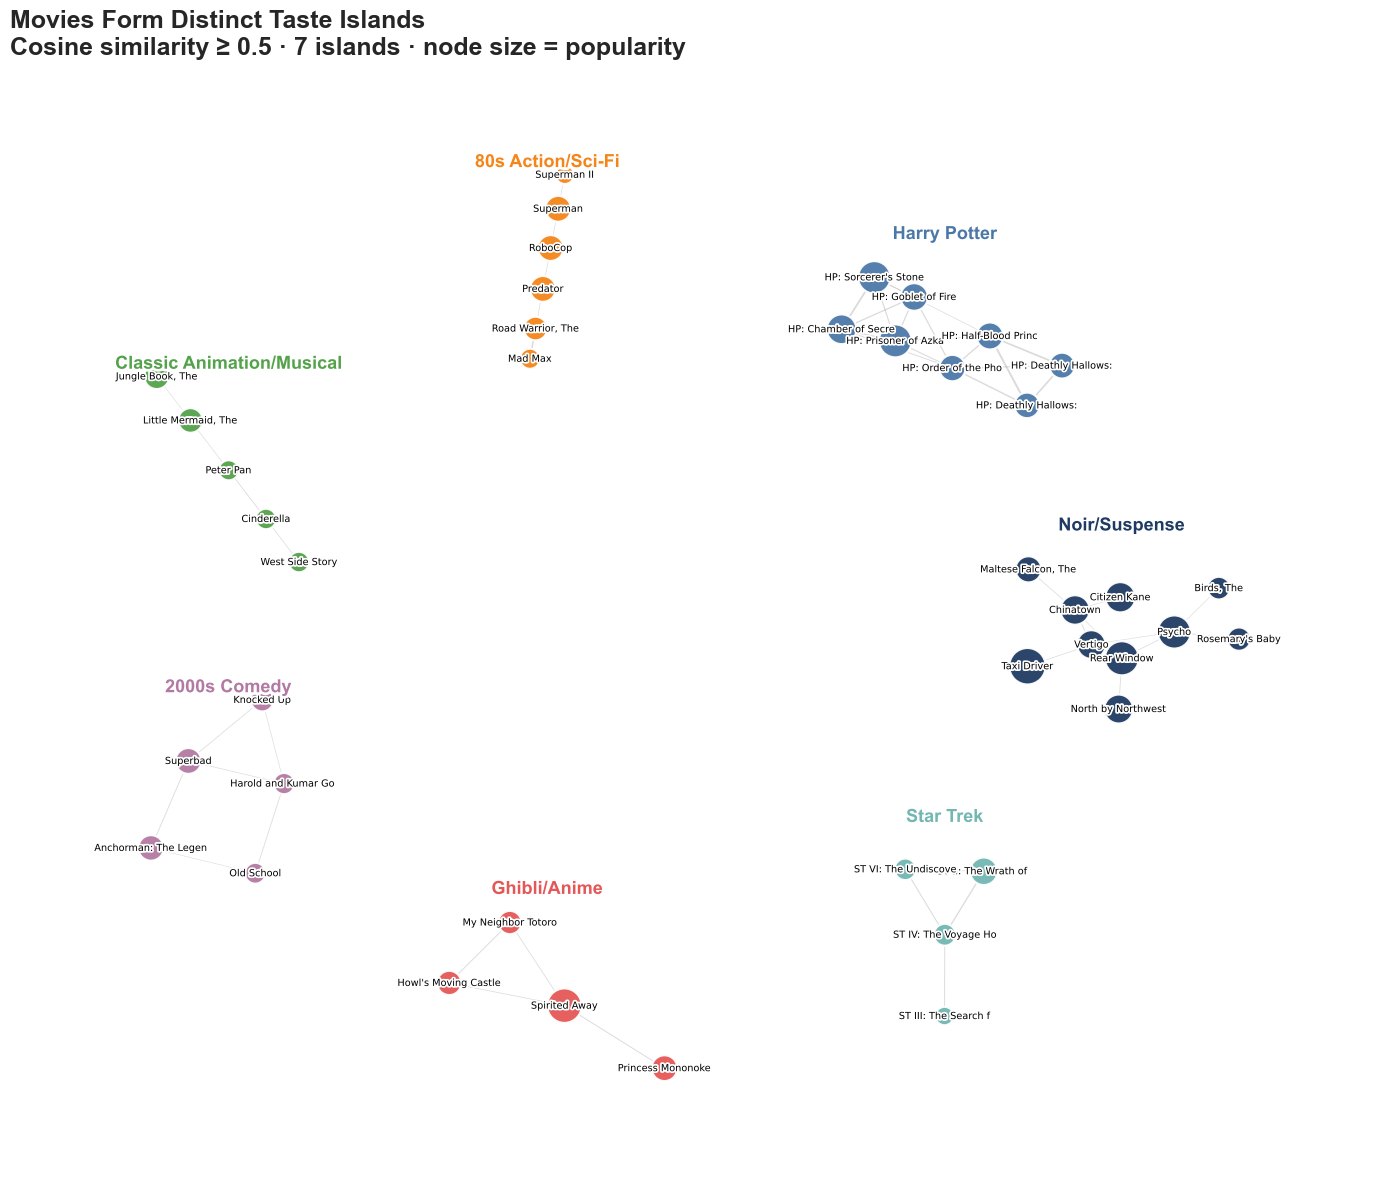

In [105]:
fig, ax = plt.subplots(figsize=(14, 12))

# --- Movie island network (islands only, no grey core) ---
MA = nx.Graph()
island_movies = [m for m in movie_color if m in pos]
MA.add_nodes_from(island_movies)
for a, b, d in C.edges(data=True):
    if (d["weight"] >= CUTOFF
        and a in pos and b in pos
        and a in movie_color and b in movie_color):
        MA.add_edge(a, b, weight=d["weight"])

# --- Edges (subtle, thin) ---
nx.draw_networkx_edges(MA, pos, ax=ax, alpha=0.30,
                       edge_color="#888888",
                       width=[0.4 + 4 * (d["weight"] - CUTOFF)
                              for _, _, d in MA.edges(data=True)])

# --- Nodes (VISIBLE now) ---
capped_size = {m: 80 + min(movie_pop[m], 80) * 8 for m in MA}
nx.draw_networkx_nodes(MA, pos, ax=ax,
                       node_color=[movie_color[m] for m in MA],
                       node_size=[capped_size[m] for m in MA],
                       edgecolors="white", linewidths=1.5, alpha=0.95)

# --- Labels with white stroke ---
def smart_short(m, maxlen=20):
    t = title[m].split("(")[0].strip()
    if "Harry Potter" in t:
        return t.replace("Harry Potter and the", "HP:").strip()[:maxlen]
    if "Star Trek" in t:
        return t.replace("Star Trek", "ST").strip()[:maxlen]
    return t[:maxlen]

labels_to_show = {m: smart_short(m) for m in MA}
texts = nx.draw_networkx_labels(MA, pos, ax=ax,
                                labels=labels_to_show,
                                font_size=7, font_family="DejaVu Sans")
for t in texts.values():
    t.set_path_effects([patheffects.withStroke(linewidth=2.5, foreground="white")])

# --- Island titles (bold, darker, above each island) ---
for lab, (cx, cy) in centres.items():
    ax.text(cx, cy + 2.6, lab, ha="center", va="bottom", fontsize=13,
            fontweight="bold", color=lab_color[lab],
            path_effects=[patheffects.withStroke(linewidth=4, foreground="white")])

# --- Trim whitespace ---
all_x = [p[0] for p in pos.values()]
all_y = [p[1] for p in pos.values()]
ax.set_xlim(min(all_x) - 3, max(all_x) + 3)
ax.set_ylim(min(all_y) - 3, max(all_y) + 3)

ax.set_title(
    "Movies Form Distinct Taste Islands\n"
    f"Cosine similarity ≥ {CUTOFF} · {len(islands)} islands · node size = popularity",
    fontsize=18, fontweight="bold", loc="left"
)
ax.axis("off")
plt.tight_layout()
plt.show()

**Key Findings:**
-   **Movies form distinct communities:** The network clearly fragments into isolated, interpretable "islands" based on shared audience tastes, separating cleanly into distinct groups like Noir/Suspense, 80s Action, and 2000s Comedy.

-   **Franchises and genres are the strongest ties:** The tightest clusters occur around film series (like Harry Potter) and highly specific genres (like Classic Musicals), where audiences overlap almost entirely.

-   **Eras define taste as much as genre:** The network reveals temporal islands—such as 1980s Sci-Fi and mid-2000s Comedies: demonstrating that viewers group films by release era as strongly as by genre.

**Visual proof of reduction:** The clear separation of these clusters proves that using cosine normalization and a 0.50 threshold successfully bypasses the "popularity bias" that keeps the raw network a single giant blob.

## Most Islands Share Few Users

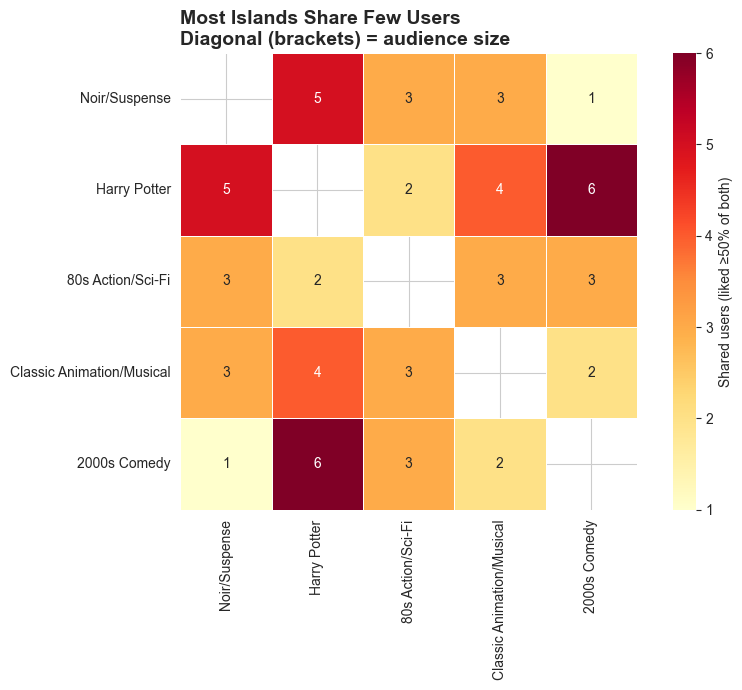

In [106]:
valid_labels = [l for l in labels if l in share.columns]
overlap = pd.DataFrame(0, index=valid_labels, columns=valid_labels, dtype=int)

for lab1 in valid_labels:
    u1 = set(share.index[share[lab1] >= 0.5])
    for lab2 in valid_labels:
        u2 = set(share.index[share[lab2] >= 0.5])
        overlap.loc[lab1, lab2] = len(u1 & u2)

diag = overlap.values.diagonal().copy()
annot = overlap.astype(str)
for i, lab in enumerate(valid_labels):
    annot.loc[lab, lab] = f"({diag[i]})"

plot_matrix = overlap.astype(float).copy()
np.fill_diagonal(plot_matrix.values, np.nan)

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(plot_matrix, annot=annot, fmt="", cmap="YlOrRd",
            square=True, ax=ax, linewidths=0.5, linecolor="white",
            cbar_kws={"label": "Shared users (liked ≥50% of both)"})
ax.set_title("Most Islands Share Few Users\nDiagonal (brackets) = audience size",
             fontsize=14, fontweight="bold", loc="left")
ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout()
plt.show()

In [107]:
# Compute the headline number
multi_island_users = (engaged > 1).sum()
total_engaged = (engaged > 0).sum()

fig.text(0.5, -0.02,
         f"Only {multi_island_users} of {total_engaged} engaged users ("
         f"{100*multi_island_users/total_engaged:.0f}%) love more than one island",
         ha="center", fontsize=13, style="italic", color="darkred")

Text(0.5, -0.02, 'Only 21 of 103 engaged users (20%) love more than one island')

**Visualization interpretation:**

**Movies Form Tight, Interpretable Clusters:** The left panel confirms the reduction method was successful. The network fragments into clear, distinct "islands" that perfectly align with intuitive categories like franchises (Harry Potter), genres (Noir/Suspense), and eras (80s Action, 2000s Comedy).

**Movies are Clustered; Users are Overlapping:** The right panel reveals a crucial asymmetry between the two groups. While movies form exclusive groups, users (squares) do not. The dense web of cross-colored lines shows that users who love one island frequently rate movies in other islands, indicating overlapping and varied tastes rather than isolated communities.

**Popularity Drives Network Structure:** In both graphs, node size (representing high ratings) highlights that the most highly-rated movies and the most active users act as the central hubs, connecting the distinct clusters together into a broader taste network.

## Which Islands have the same fans?

Showing overlaps for 21 users engaged with multiple islands.


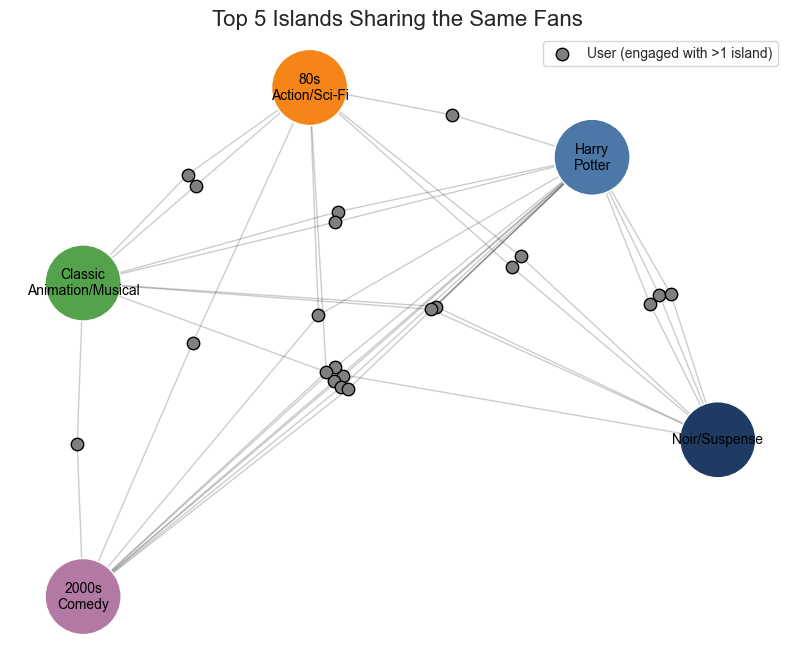

In [108]:
# Find users who are engaged with more than one island
multi_island_users = engaged[engaged > 1].index
print(f"Showing overlaps for {len(multi_island_users)} users engaged with multiple islands.")

# Create a new bipartite graph centered on island labels
G3 = nx.Graph()
island_nodes = labels
G3.add_nodes_from(island_nodes, bipartite=0) # Islands

# Add users as nodes and connect them to the islands they engage with
for u in multi_island_users:
    G3.add_node(u, bipartite=1) # Users
    for lab in share.columns:
        if share.loc[u, lab] >= 0.5: # User is engaged with this island
            G3.add_edge(lab, u)

# --- MINIMUM CHANGE 1: Get top 5 islands by degree (number of user connections) ---
top_5_islands = [node for node, degree in sorted(G3.degree(island_nodes), key=lambda x: x[1], reverse=True)[:5]]
# Filter your island_nodes and palette to only keep the top 5
island_nodes = top_5_islands
if isinstance(palette, dict):
    palette = {k: palette[k] for k in island_nodes}
else:
    # Assumes palette is a list matching original order, find their indices
    original_order = list(labels)
    palette = [palette[original_order.index(lab)] for lab in island_nodes]

# Position islands in a circle
pos_islands = {lab: centres[lab] for lab in island_nodes}
pos_users = nx.spring_layout(G3, pos=pos_islands, fixed=list(island_nodes), k=0.9, iterations=50)

fig, ax = plt.subplots(figsize=(10, 8))
# --- MINIMUM CHANGE 2: Changed nodelist to island_nodes ---
nx.draw_networkx_edges(G3, pos_users, ax=ax, alpha=0.2)
nx.draw_networkx_nodes(G3, pos_users, ax=ax, nodelist=island_nodes, node_size=3000, node_color=palette, edgecolors='white')
nx.draw_networkx_labels(G3, pos_users, ax=ax, labels={lab: lab.replace(" ", "\n") for lab in island_nodes}, font_size=10)

# --- MINIMUM CHANGE 3: Filter multi_island_users to only those connected to the top 5 ---
# This prevents errors/ghost nodes from users who only connect to islands that are now hidden
valid_users = [u for u in multi_island_users if any(G3.has_edge(lab, u) for lab in island_nodes)]
nx.draw_networkx_nodes(G3, pos_users, ax=ax, nodelist=valid_users, node_size=80, node_color='grey', edgecolors='black', label='User (engaged with >1 island)')

ax.set_title("Top 5 Islands Sharing the Same Fans", fontsize=16)
ax.legend()
ax.axis('off')
plt.show()

**Interpretation**

**Users are boundary spanners, not isolated tribes:** The grey dots represent the minority of users who cross over, connecting the different movie islands rather than staying in a single silo.

**The "Classics" bridge dominates:** The 80s Action/Sci-Fi and Classic Animation islands share the most overlapping fans, suggesting a unified "older/classic film" audience.

**Harry Potter fans are highly cross-pollinated:** The Harry Potter hub has many connections, showing that its fans also actively engage with 2000s Comedies and Noir/Suspense.

**No two islands share a massive audience:** The relatively thin web of connections proves that while taste groups overlap slightly, they remain largely distinct communities.

### Key Findings

**About Movies:**

Movies form tight, interpretable clusters organized around franchises (Harry Potter, Star Trek), genres (Noir, Westerns, Animation), and eras (1950s thrillers, 1980s action, 2000s comedy). These islands are the strongest structure in the network.

**About Users:**

Users are a broad, overlapping audience, not a set of isolated communities. Most users do not belong to any single taste group. Those who do engage with an island typically love only one, and cross-island correlations are weak. Heavy raters span the most islands.

**About the Method:**

The island method alone is insufficient for dense bipartite networks. Successful community detection required a multi-step approach: pruning weak nodes, projecting to a one-mode network, and cosine normalization to remove popularity bias. Only after these steps did meaningful islands emerge.

**The Asymmetry:**

Movies are clustered and specific; users are overlapping and general. This is the central insight of the analysis.